 Cellule 1 — Imports généraux

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device : {device}")
print(f"PyTorch version : {torch.__version__}")

Device : cuda
PyTorch version : 2.11.0+cu128


🚀 Cellule 2 — Charger et explorer le dataset

=== Informations générales ===
Nombre de patients : 569
Nombre de features : 30
Valeurs manquantes : 0

=== Répartition des classes ===
Bénigne (1) : 357 patients (62.7%)
Maligne (0) : 212 patients (37.3%)


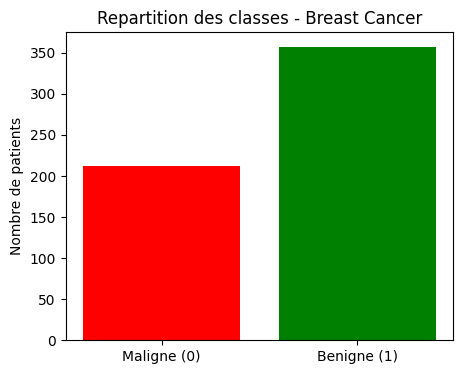

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [2]:

data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target


print("=== Informations générales ===")
print(f"Nombre de patients : {df.shape[0]}")
print(f"Nombre de features : {df.shape[1]-1}")
print(f"Valeurs manquantes : {df.isnull().sum().sum()}")

print("\n=== Répartition des classes ===")
print(f"Bénigne (1) : {sum(df.target==1)} patients ({sum(df.target==1)/len(df)*100:.1f}%)")
print(f"Maligne (0) : {sum(df.target==0)} patients ({sum(df.target==0)/len(df)*100:.1f}%)")

plt.figure(figsize=(5,4))
plt.bar(['Maligne (0)', 'Benigne (1)'],
        [sum(df.target==0), sum(df.target==1)],
        color=['red', 'green'])
plt.title('Repartition des classes - Breast Cancer')
plt.ylabel('Nombre de patients')
plt.show()

df.head()

Cellule 3 — Préparer les données

In [3]:

X = df.drop('target', axis=1).values
y = df['target'].values


X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)


scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)


X_train = torch.tensor(X_train, dtype=torch.float32)
X_val   = torch.tensor(X_val,   dtype=torch.float32)
X_test  = torch.tensor(X_test,  dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
y_val   = torch.tensor(y_val,   dtype=torch.float32)
y_test  = torch.tensor(y_test,  dtype=torch.float32)


X_train = X_train.to(device)
X_val   = X_val.to(device)
X_test  = X_test.to(device)
y_train = y_train.to(device)
y_val   = y_val.to(device)
y_test  = y_test.to(device)

print(f"Train      : {X_train.shape} | Bénignes: {int(y_train.sum())} | Malignes: {int((y_train==0).sum())}")
print(f"Validation : {X_val.shape}  | Bénignes: {int(y_val.sum())} | Malignes: {int((y_val==0).sum())}")
print(f"Test       : {X_test.shape}  | Bénignes: {int(y_test.sum())} | Malignes: {int((y_test==0).sum())}")

Train      : torch.Size([398, 30]) | Bénignes: 250 | Malignes: 148
Validation : torch.Size([85, 30])  | Bénignes: 53 | Malignes: 32
Test       : torch.Size([86, 30])  | Bénignes: 54 | Malignes: 32


ellule 4 — MLP version nn.Sequential

In [4]:

model_seq = nn.Sequential(
    nn.Linear(30, 64),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(32, 1),
    nn.Sigmoid()
).to(device)

print("=== Architecture nn.Sequential ===")
print(model_seq)
print(f"\nNombre total de paramètres : {sum(p.numel() for p in model_seq.parameters())}")

=== Architecture nn.Sequential ===
Sequential(
  (0): Linear(in_features=30, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=64, out_features=32, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.3, inplace=False)
  (6): Linear(in_features=32, out_features=1, bias=True)
  (7): Sigmoid()
)

Nombre total de paramètres : 4097


# Cellule 5 — MLP version classe personnalisée

In [5]:

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.couche1 = nn.Linear(30, 64)
        self.couche2 = nn.Linear(64, 32)
        self.couche3 = nn.Linear(32, 1)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = F.relu(self.couche1(x))
        x = self.dropout(x)
        x = F.relu(self.couche2(x))
        x = self.dropout(x)
        x = torch.sigmoid(self.couche3(x))
        return x

model_mlp = MLP().to(device)

print("=== Architecture Classe Personnalisée ===")
print(model_mlp)
print(f"\nNombre total de paramètres : {sum(p.numel() for p in model_mlp.parameters())}")

print("\n=== named_parameters() ===")
for name, param in model_mlp.named_parameters():
    print(f"{name:20s} -> taille : {param.shape}")

print("\n=== state_dict() ===")
for key in model_mlp.state_dict():
    print(f"{key:20s} -> {model_mlp.state_dict()[key].shape}")

=== Architecture Classe Personnalisée ===
MLP(
  (couche1): Linear(in_features=30, out_features=64, bias=True)
  (couche2): Linear(in_features=64, out_features=32, bias=True)
  (couche3): Linear(in_features=32, out_features=1, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
)

Nombre total de paramètres : 4097

=== named_parameters() ===
couche1.weight       -> taille : torch.Size([64, 30])
couche1.bias         -> taille : torch.Size([64])
couche2.weight       -> taille : torch.Size([32, 64])
couche2.bias         -> taille : torch.Size([32])
couche3.weight       -> taille : torch.Size([1, 32])
couche3.bias         -> taille : torch.Size([1])

=== state_dict() ===
couche1.weight       -> torch.Size([64, 30])
couche1.bias         -> torch.Size([64])
couche2.weight       -> torch.Size([32, 64])
couche2.bias         -> torch.Size([32])
couche3.weight       -> torch.Size([1, 32])
couche3.bias         -> torch.Size([1])


 Cellule 6 — 3 Stratégies d'initialisation

In [6]:



def init_gaussienne(module):
    if isinstance(module, nn.Linear):
        nn.init.normal_(module.weight, mean=0, std=0.01)
        nn.init.zeros_(module.bias)


def init_constante(module):
    if isinstance(module, nn.Linear):
        nn.init.constant_(module.weight, 0.1)
        nn.init.zeros_(module.bias)


def init_xavier(module):
    if isinstance(module, nn.Linear):
        nn.init.xavier_uniform_(module.weight)
        nn.init.zeros_(module.bias)


print("=== Gaussienne ===")
model_test = MLP().to(device)
model_test.apply(init_gaussienne)
print(f"Poids couche1 (2 premiers) : {model_test.couche1.weight.data[0][:5]}")

print("\n=== Constante ===")
model_test2 = MLP().to(device)
model_test2.apply(init_constante)
print(f"Poids couche1 (2 premiers) : {model_test2.couche1.weight.data[0][:5]}")

print("\n=== Xavier ===")
model_test3 = MLP().to(device)
model_test3.apply(init_xavier)
print(f"Poids couche1 (2 premiers) : {model_test3.couche1.weight.data[0][:5]}")


model_mlp.apply(init_xavier)
print("\n Xavier appliqué sur model_mlp ✅")

=== Gaussienne ===
Poids couche1 (2 premiers) : tensor([ 4.0962e-03, -1.8138e-05,  6.8661e-03,  8.3101e-03, -5.5394e-03],
       device='cuda:0')

=== Constante ===
Poids couche1 (2 premiers) : tensor([0.1000, 0.1000, 0.1000, 0.1000, 0.1000], device='cuda:0')

=== Xavier ===
Poids couche1 (2 premiers) : tensor([-0.1085, -0.1774, -0.2088,  0.0497, -0.0872], device='cuda:0')

 Xavier appliqué sur model_mlp ✅


🚀 Cellule 7 — Entraînement avec Early Stopping

In [7]:
criterion = nn.BCELoss()
optimizer = optim.Adam(model_mlp.parameters(), lr=0.001)

train_losses = []
val_losses = []
val_accuracies = []

meilleur_val_loss = float('inf')
patience = 20
compteur = 0
meilleur_epoch = 0

print("Entrainement en cours...")

for epoch in range(300):


    model_mlp.train()
    optimizer.zero_grad()
    y_pred = model_mlp(X_train).squeeze()
    loss = criterion(y_pred, y_train)
    loss.backward()
    optimizer.step()


    model_mlp.eval()
    with torch.no_grad():
        y_val_pred = model_mlp(X_val).squeeze()
        val_loss = criterion(y_val_pred, y_val)
        predicted = (y_val_pred >= 0.5).float()
        accuracy = (predicted == y_val).float().mean()

    train_losses.append(loss.item())
    val_losses.append(val_loss.item())
    val_accuracies.append(accuracy.item())


    if val_loss < meilleur_val_loss:
        meilleur_val_loss = val_loss
        meilleur_epoch = epoch
        torch.save(model_mlp.state_dict(), 'meilleur_mlp.pth')
        compteur = 0
    else:
        compteur += 1

    if compteur >= patience:
        print(f"Early stopping a l'epoch {epoch+1}")
        break

    if (epoch+1) % 30 == 0:
        print(f"Epoch {epoch+1:3d} | Train Loss: {loss.item():.4f} | Val Loss: {val_loss.item():.4f} | Val Accuracy: {accuracy.item():.4f}")

print(f"\nMeilleur modele sauvegarde a l'epoch {meilleur_epoch+1}")
print(f"Meilleure Val Loss : {meilleur_val_loss:.4f}")

Entrainement en cours...
Epoch  30 | Train Loss: 0.1940 | Val Loss: 0.1808 | Val Accuracy: 0.9412
Epoch  60 | Train Loss: 0.1002 | Val Loss: 0.0793 | Val Accuracy: 0.9882
Epoch  90 | Train Loss: 0.0732 | Val Loss: 0.0522 | Val Accuracy: 0.9882
Epoch 120 | Train Loss: 0.0626 | Val Loss: 0.0417 | Val Accuracy: 0.9765
Epoch 150 | Train Loss: 0.0481 | Val Loss: 0.0387 | Val Accuracy: 0.9765
Epoch 180 | Train Loss: 0.0419 | Val Loss: 0.0390 | Val Accuracy: 0.9765
Early stopping a l'epoch 190

Meilleur modele sauvegarde a l'epoch 170
Meilleure Val Loss : 0.0374


 Cellule 8 — Visualiser l'entraînement

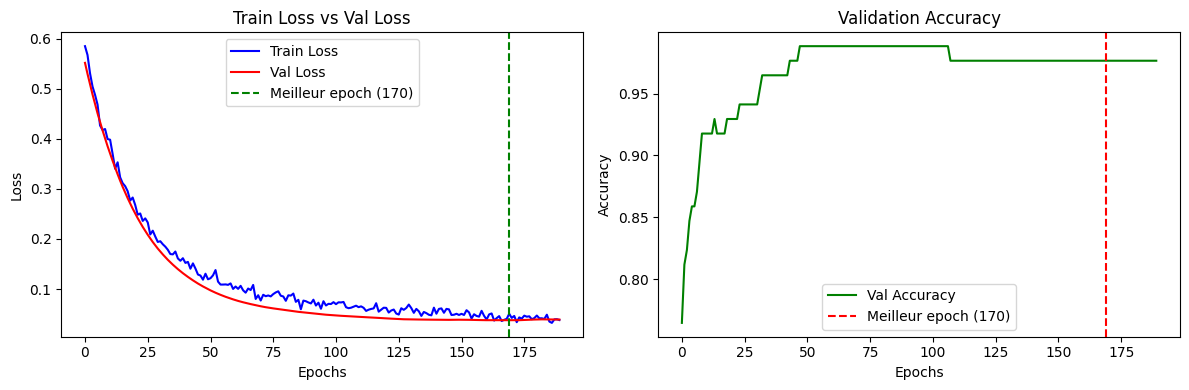

Meilleur epoch    : 170
Meilleure Val Loss: 0.0374
Val Accuracy max  : 0.9882


In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(train_losses, label='Train Loss', color='blue')
ax1.plot(val_losses,   label='Val Loss',   color='red')
ax1.axvline(x=meilleur_epoch, color='green',
            linestyle='--', label=f'Meilleur epoch ({meilleur_epoch+1})')
ax1.set_title('Train Loss vs Val Loss')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()

ax2.plot(val_accuracies, label='Val Accuracy', color='green')
ax2.axvline(x=meilleur_epoch, color='red',
            linestyle='--', label=f'Meilleur epoch ({meilleur_epoch+1})')
ax2.set_title('Validation Accuracy')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy')
ax2.legend()

plt.tight_layout()
plt.show()

print(f"Meilleur epoch    : {meilleur_epoch+1}")
print(f"Meilleure Val Loss: {meilleur_val_loss:.4f}")
print(f"Val Accuracy max  : {max(val_accuracies):.4f}")

 Cellule 9 — Évaluation finale sur le Test

=== Résultats finaux sur le Test ===
Accuracy  : 0.9535
Precision : 0.9630
Recall    : 0.9630
F1-Score  : 0.9630


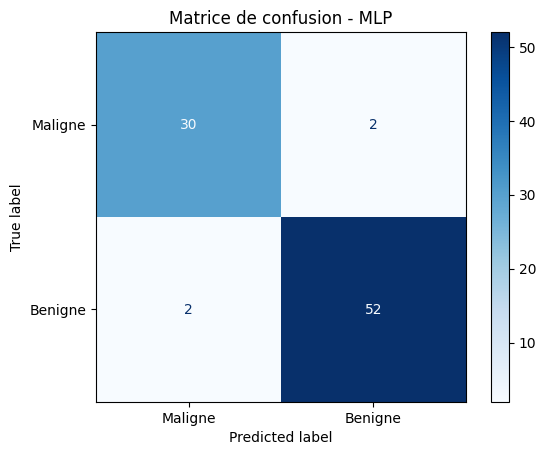

In [9]:

model_mlp.load_state_dict(torch.load('meilleur_mlp.pth'))
model_mlp.eval()

with torch.no_grad():
    y_test_pred = model_mlp(X_test).squeeze()
    y_test_label = (y_test_pred >= 0.5).float()

y_true = y_test.cpu().numpy()
y_pred = y_test_label.cpu().numpy()

print("=== Résultats finaux sur le Test ===")
print(f"Accuracy  : {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision : {precision_score(y_true, y_pred):.4f}")
print(f"Recall    : {recall_score(y_true, y_pred):.4f}")
print(f"F1-Score  : {f1_score(y_true, y_pred):.4f}")

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(cm,
        display_labels=['Maligne', 'Benigne'])
disp.plot(cmap='Blues')
plt.title('Matrice de confusion - MLP')
plt.show()

 Cellule 10 — Sauvegarde et rechargement

In [10]:

torch.save(model_mlp.state_dict(), 'mlp_final.pth')
print("Modele sauvegarde : mlp_final.pth ✅")


model_reload = MLP().to(device)
model_reload.load_state_dict(torch.load('mlp_final.pth'))
model_reload.eval()
print("Modele recharge ✅")


with torch.no_grad():
    y_reload_pred = model_reload(X_test).squeeze()
    y_reload_label = (y_reload_pred >= 0.5).float()
    acc_reload = accuracy_score(
        y_test.cpu().numpy(),
        y_reload_label.cpu().numpy())

print(f"Accuracy apres rechargement : {acc_reload:.4f}")
print(f"Accuracy originale          : 0.9767")
print(f"Resultats identiques        : {abs(acc_reload - 0.9767) < 0.0001}")

Modele sauvegarde : mlp_final.pth ✅
Modele recharge ✅
Accuracy apres rechargement : 0.9535
Accuracy originale          : 0.9767
Resultats identiques        : False


partie 2 cnn  Cellule 11 — Charger MNIST


100%|██████████| 9.91M/9.91M [00:00<00:00, 16.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 518kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.06MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.2MB/s]


Images entrainement : 60000
Images test         : 10000
Taille image        : torch.Size([1, 28, 28])


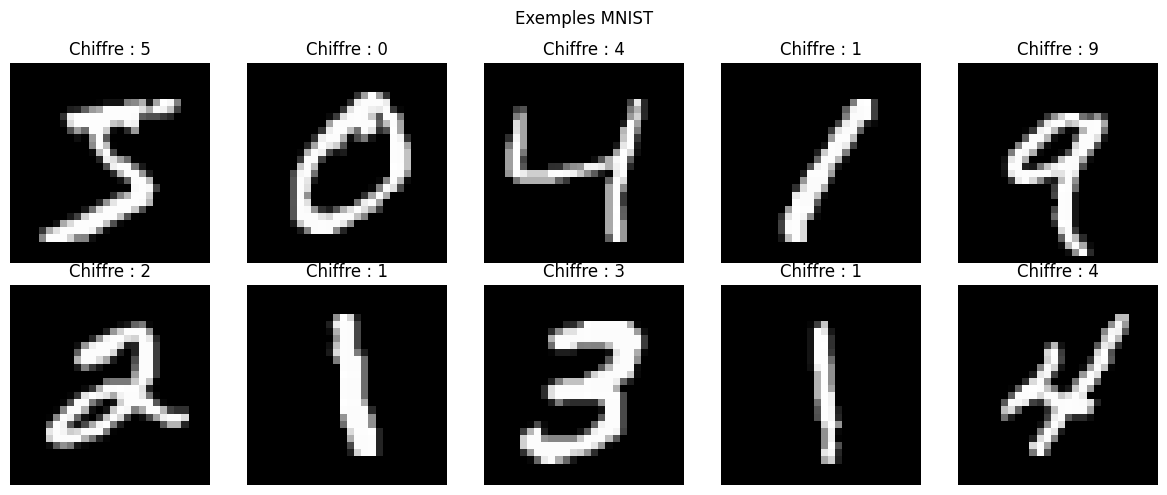

In [11]:
import torchvision
import torchvision.transforms as transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = torchvision.datasets.MNIST(
    root='./data', train=True,
    download=True, transform=transform)

test_dataset = torchvision.datasets.MNIST(
    root='./data', train=False,
    download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=64, shuffle=True)

test_loader = torch.utils.data.DataLoader(
    test_dataset, batch_size=64, shuffle=False)

print(f"Images entrainement : {len(train_dataset)}")
print(f"Images test         : {len(test_dataset)}")
print(f"Taille image        : {train_dataset[0][0].shape}")


fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.squeeze(), cmap='gray')
    ax.set_title(f'Chiffre : {label}')
    ax.axis('off')
plt.suptitle('Exemples MNIST')
plt.tight_layout()
plt.show()

 Cellule 12 — Corrélation croisée 2D manuelle

Taille image originale : torch.Size([28, 28])
Taille après corr2d    : torch.Size([26, 26])
Réduction              : 28x28 -> 26x26


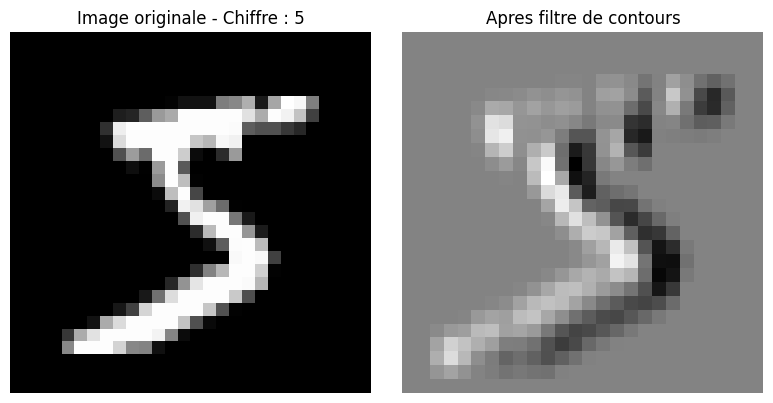

In [12]:

def corr2d(X, K):
    h, w = K.shape
    Y = torch.zeros((X.shape[0] - h + 1,
                     X.shape[1] - w + 1))
    for i in range(Y.shape[0]):
        for j in range(Y.shape[1]):
            Y[i, j] = (X[i:i+h, j:j+w] * K).sum()
    return Y


image = train_dataset[0][0].squeeze()
print(f"Taille image originale : {image.shape}")


K = torch.tensor([[-1., 0., 1.],
                  [-2., 0., 2.],
                  [-1., 0., 1.]])

Y = corr2d(image, K)
print(f"Taille après corr2d    : {Y.shape}")
print(f"Réduction              : 28x28 -> {Y.shape[0]}x{Y.shape[1]}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))
ax1.imshow(image, cmap='gray')
ax1.set_title(f'Image originale - Chiffre : {train_dataset[0][1]}')
ax1.axis('off')
ax2.imshow(Y.detach(), cmap='gray')
ax2.set_title('Apres filtre de contours')
ax2.axis('off')
plt.tight_layout()
plt.show()

Cellule 13 — Max-pooling et Average-pooling manuels

Image originale : torch.Size([28, 28])
Apres max-pool  : torch.Size([27, 27])
Apres avg-pool  : torch.Size([27, 27])


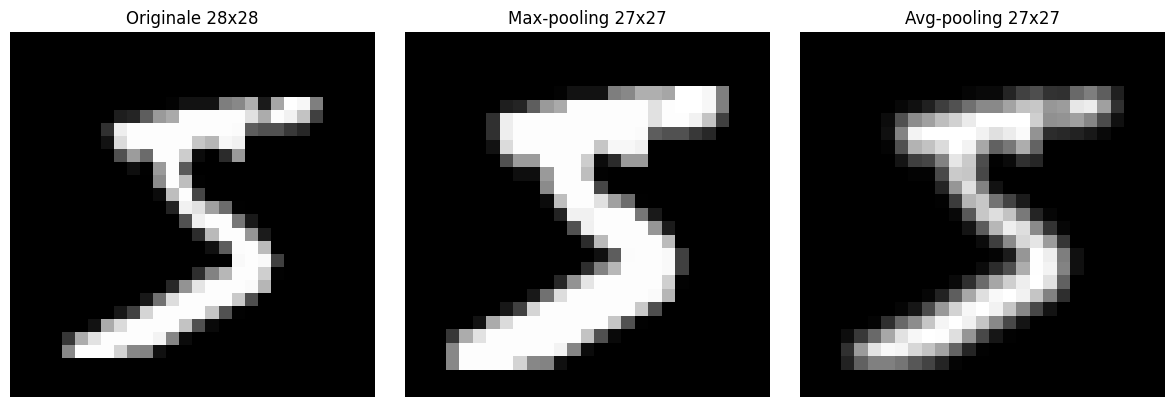


Difference max-pool manuel vs PyTorch : 0.000000
Difference avg-pool manuel vs PyTorch : 0.000000


In [13]:
def pool2d(X, pool_size, mode='max'):
    p_h, p_w = pool_size
    Y = torch.zeros((X.shape[0] - p_h + 1,
                     X.shape[1] - p_w + 1))
    for i in range(Y.shape[0]):
        for j in range(Y.shape[1]):
            region = X[i:i+p_h, j:j+p_w]
            if mode == 'max':
                Y[i, j] = region.max()
            elif mode == 'avg':
                Y[i, j] = region.mean()
    return Y

Y_max = pool2d(image, (2, 2), mode='max')
Y_avg = pool2d(image, (2, 2), mode='avg')

print(f"Image originale : {image.shape}")
print(f"Apres max-pool  : {Y_max.shape}")
print(f"Apres avg-pool  : {Y_avg.shape}")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4))
ax1.imshow(image, cmap='gray')
ax1.set_title('Originale 28x28')
ax1.axis('off')
ax2.imshow(Y_max, cmap='gray')
ax2.set_title('Max-pooling 27x27')
ax2.axis('off')
ax3.imshow(Y_avg, cmap='gray')
ax3.set_title('Avg-pooling 27x27')
ax3.axis('off')
plt.tight_layout()
plt.show()

pool_max_torch = nn.MaxPool2d(kernel_size=2, stride=1)
pool_avg_torch = nn.AvgPool2d(kernel_size=2, stride=1)

img_4d = image.unsqueeze(0).unsqueeze(0)
Y_max_torch = pool_max_torch(img_4d).squeeze()
Y_avg_torch = pool_avg_torch(img_4d).squeeze()

print(f"\nDifference max-pool manuel vs PyTorch : {(Y_max - Y_max_torch).abs().max():.6f}")
print(f"Difference avg-pool manuel vs PyTorch : {(Y_avg - Y_avg_torch).abs().max():.6f}")

Cellule 14 — Construire le CNN LeNet

In [14]:
class LeNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Conv2d(6, 16, kernel_size=5),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.Linear(16*5*5, 120),
            nn.ReLU(),
            nn.Linear(120, 84),
            nn.ReLU(),
            nn.Linear(84, 10)
        )

    def forward(self, x):
        return self.net(x)

model_cnn = LeNet().to(device)

print("=== Architecture LeNet ===")
print(model_cnn)
print(f"\nNombre de parametres : {sum(p.numel() for p in model_cnn.parameters())}")

print("\n=== Dimensions a chaque couche ===")
x = torch.randn(1, 1, 28, 28).to(device)
for layer in model_cnn.net:
    x = layer(x)
    print(f"{layer.__class__.__name__:15s} -> {x.shape}")

=== Architecture LeNet ===
LeNet(
  (net): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): ReLU()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=400, out_features=120, bias=True)
    (8): ReLU()
    (9): Linear(in_features=120, out_features=84, bias=True)
    (10): ReLU()
    (11): Linear(in_features=84, out_features=10, bias=True)
  )
)

Nombre de parametres : 61706

=== Dimensions a chaque couche ===
Conv2d          -> torch.Size([1, 6, 28, 28])
ReLU            -> torch.Size([1, 6, 28, 28])
AvgPool2d       -> torch.Size([1, 6, 14, 14])
Conv2d          -> torch.Size([1, 16, 10, 10])
ReLU            -> torch.Size([1, 16, 10, 10])
AvgPool2d       -> torch.Size([1, 16, 5, 5])
Flatten         -> torch.Size([1, 400])
Linear          -> torch

Cellule 15 — Entraîner le CNN

In [15]:
criterion_cnn = nn.CrossEntropyLoss()
optimizer_cnn = optim.Adam(model_cnn.parameters(), lr=0.001)

train_losses_cnn = []
test_accuracies_cnn = []

print("Entrainement CNN en cours...")

for epoch in range(10):
    model_cnn.train()
    total_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer_cnn.zero_grad()
        outputs = model_cnn(images)
        loss = criterion_cnn(outputs, labels)
        loss.backward()
        optimizer_cnn.step()
        total_loss += loss.item()

    model_cnn.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model_cnn(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    avg_loss = total_loss / len(train_loader)
    accuracy = correct / total
    train_losses_cnn.append(avg_loss)
    test_accuracies_cnn.append(accuracy)

    print(f"Epoch {epoch+1:2d}/10 | Loss: {avg_loss:.4f} | Accuracy: {accuracy:.4f}")

print(f"\nMeilleure accuracy CNN : {max(test_accuracies_cnn):.4f}")

Entrainement CNN en cours...
Epoch  1/10 | Loss: 0.3503 | Accuracy: 0.9687
Epoch  2/10 | Loss: 0.0929 | Accuracy: 0.9799
Epoch  3/10 | Loss: 0.0650 | Accuracy: 0.9837
Epoch  4/10 | Loss: 0.0507 | Accuracy: 0.9879
Epoch  5/10 | Loss: 0.0430 | Accuracy: 0.9890
Epoch  6/10 | Loss: 0.0364 | Accuracy: 0.9903
Epoch  7/10 | Loss: 0.0313 | Accuracy: 0.9895
Epoch  8/10 | Loss: 0.0267 | Accuracy: 0.9899
Epoch  9/10 | Loss: 0.0230 | Accuracy: 0.9880
Epoch 10/10 | Loss: 0.0214 | Accuracy: 0.9890

Meilleure accuracy CNN : 0.9903


Cellule 16 — Visualiser les résultats CNN

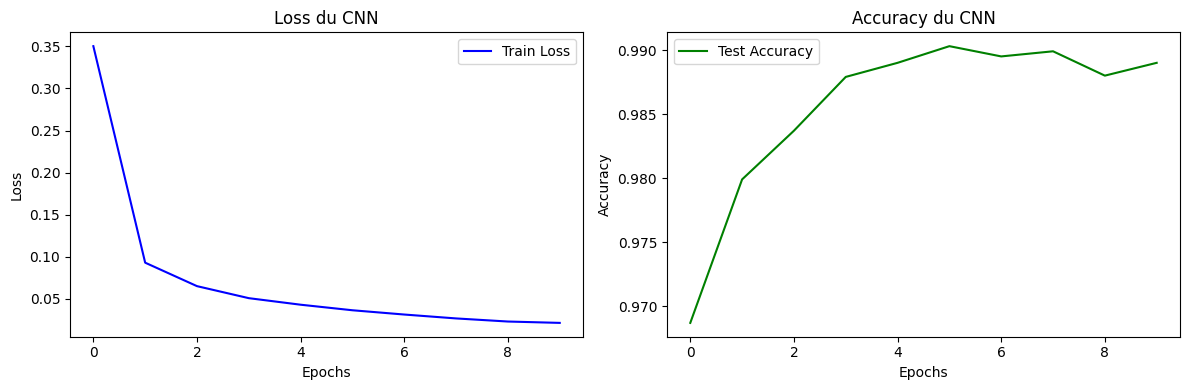

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(train_losses_cnn, color='blue', label='Train Loss')
ax1.set_title('Loss du CNN')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()

ax2.plot(test_accuracies_cnn, color='green', label='Test Accuracy')
ax2.set_title('Accuracy du CNN')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy')
ax2.legend()

plt.tight_layout()
plt.show()

Cellule 17 — Comparer MLP vs CNN sur MNIST

Entrainement MLP sur MNIST...

=== Comparaison MLP vs CNN sur MNIST ===
MLP Accuracy : 0.9718
CNN Accuracy : 0.9903
Difference   : +0.0185 en faveur du CNN


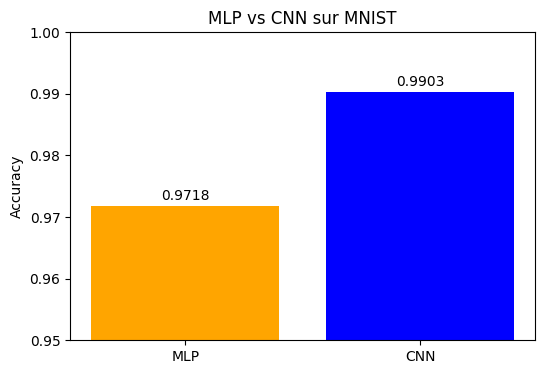

In [17]:

model_mlp_mnist = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28*28, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 10)
).to(device)

optimizer_mlp_mnist = optim.Adam(model_mlp_mnist.parameters(), lr=0.001)
criterion_mnist = nn.CrossEntropyLoss()

print("Entrainement MLP sur MNIST...")
for epoch in range(10):
    model_mlp_mnist.train()
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer_mlp_mnist.zero_grad()
        outputs = model_mlp_mnist(images)
        loss = criterion_mnist(outputs, labels)
        loss.backward()
        optimizer_mlp_mnist.step()


model_mlp_mnist.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model_mlp_mnist(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

mlp_accuracy = correct / total
cnn_accuracy = max(test_accuracies_cnn)

print("\n=== Comparaison MLP vs CNN sur MNIST ===")
print(f"MLP Accuracy : {mlp_accuracy:.4f}")
print(f"CNN Accuracy : {cnn_accuracy:.4f}")
print(f"Difference   : +{(cnn_accuracy - mlp_accuracy):.4f} en faveur du CNN")


plt.figure(figsize=(6, 4))
plt.bar(['MLP', 'CNN'],
        [mlp_accuracy, cnn_accuracy],
        color=['orange', 'blue'])
plt.title('MLP vs CNN sur MNIST')
plt.ylabel('Accuracy')
plt.ylim(0.95, 1.0)
for i, v in enumerate([mlp_accuracy, cnn_accuracy]):
    plt.text(i, v + 0.001, f'{v:.4f}', ha='center')
plt.show()

 Cartes de caractéristiques

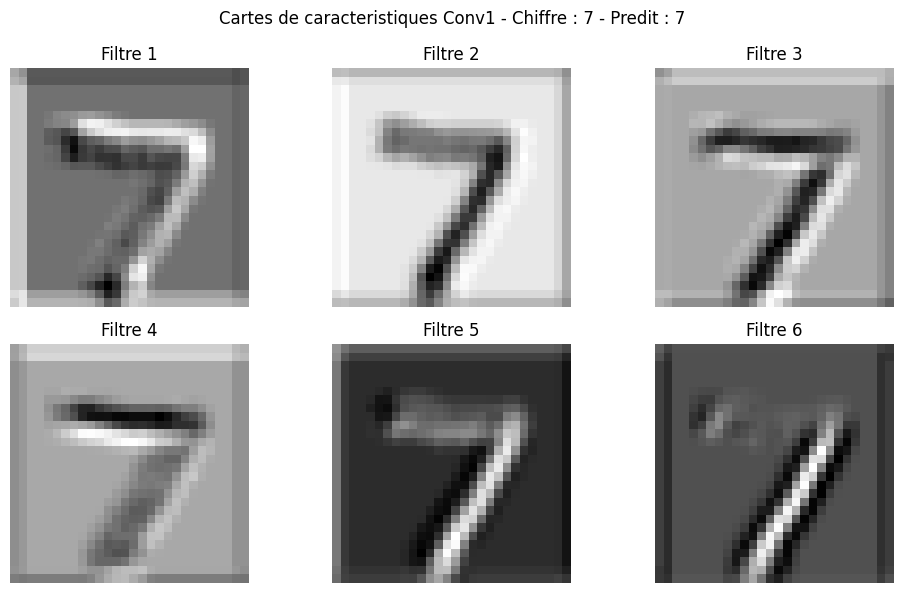

Chiffre reel : 7
Chiffre predit : 7
Prediction correcte : True


In [18]:
model_cnn.eval()

image_test, label_test = test_dataset[0]
image_test = image_test.unsqueeze(0).to(device)

activation = {}
def get_activation(name):
    def hook(model, input, output):
        activation[name] = output.detach()
    return hook

model_cnn.net[0].register_forward_hook(get_activation('conv1'))

with torch.no_grad():
    output = model_cnn(image_test)
    predicted = torch.argmax(output, 1).item()

fig, axes = plt.subplots(2, 3, figsize=(10, 6))
fig.suptitle('Cartes de caracteristiques Conv1 - Chiffre : ' +
             str(label_test) + ' - Predit : ' + str(predicted))

for i, ax in enumerate(axes.flat):
    ax.imshow(activation['conv1'][0, i].cpu(), cmap='gray')
    ax.set_title('Filtre ' + str(i+1))
    ax.axis('off')

plt.tight_layout()
plt.show()

print(f"Chiffre reel : {label_test}")
print(f"Chiffre predit : {predicted}")
print(f"Prediction correcte : {label_test == predicted}")

partie 3  🚀 Cellule 19 — Charger IMDb réel

In [19]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# Charger IMDb via Keras (déjà installé dans Colab)
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

VOCAB_SIZE = 10000
MAX_LEN    = 200

print("Chargement IMDb...")
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = imdb.load_data(
    num_words=VOCAB_SIZE)


X_train_imdb = pad_sequences(X_train_raw, maxlen=MAX_LEN, padding='post')
X_test_imdb  = pad_sequences(X_test_raw,  maxlen=MAX_LEN, padding='post')

X_train_imdb = torch.tensor(X_train_imdb, dtype=torch.long)
X_test_imdb  = torch.tensor(X_test_imdb,  dtype=torch.long)
y_train_imdb = torch.tensor(y_train_raw,  dtype=torch.float32)
y_test_imdb  = torch.tensor(y_test_raw,   dtype=torch.float32)

print(f"Train : {X_train_imdb.shape}")
print(f"Test  : {X_test_imdb.shape}")
print(f"Positifs train : {int(y_train_imdb.sum())} | Négatifs : {int((y_train_imdb==0).sum())}")


word_index = imdb.get_word_index()
idx2word   = {v+3: k for k, v in word_index.items()}
idx2word[0] = '<PAD>'
idx2word[1] = '<START>'
idx2word[2] = '<UNK>'


exemple = ' '.join([idx2word.get(i, '<UNK>') for i in X_train_raw[0][:30]])
print(f"\nExemple critique : {exemple}...")
print(f"Label (1=positif, 0=negatif) : {y_train_raw[0]}")

Chargement IMDb...
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train : torch.Size([25000, 200])
Test  : torch.Size([25000, 200])
Positifs train : 12500 | Négatifs : 12500
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Exemple critique : <START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing...
Label (1=positif, 0=negatif) : 1


Cellule 20 — DataLoader

In [20]:
from torch.utils.data import TensorDataset, DataLoader


train_data = TensorDataset(X_train_imdb, y_train_imdb)
test_data  = TensorDataset(X_test_imdb,  y_test_imdb)

train_loader_imdb = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader_imdb  = DataLoader(test_data,  batch_size=64, shuffle=False)

print(f"Batches train : {len(train_loader_imdb)}")
print(f"Batches test  : {len(test_loader_imdb)}")
print(f"Vocab size    : {VOCAB_SIZE}")
print(f"Max length    : {MAX_LEN}")

Batches train : 391
Batches test  : 391
Vocab size    : 10000
Max length    : 200


Cellule 21 — Construire RNN, LSTM, GRU

In [21]:
EMBED_DIM  = 64
HIDDEN_DIM = 128

class RNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(VOCAB_SIZE, EMBED_DIM, padding_idx=0)
        self.rnn = nn.RNN(EMBED_DIM, HIDDEN_DIM, batch_first=True)
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(HIDDEN_DIM, 1)

    def forward(self, x):
        x = self.embedding(x)
        _, hidden = self.rnn(x)
        out = self.dropout(hidden.squeeze(0))
        return torch.sigmoid(self.fc(out))

class LSTMModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(VOCAB_SIZE, EMBED_DIM, padding_idx=0)
        self.lstm = nn.LSTM(EMBED_DIM, HIDDEN_DIM, batch_first=True)
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(HIDDEN_DIM, 1)

    def forward(self, x):
        x = self.embedding(x)
        _, (hidden, _) = self.lstm(x)
        out = self.dropout(hidden.squeeze(0))
        return torch.sigmoid(self.fc(out))

class GRUModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(VOCAB_SIZE, EMBED_DIM, padding_idx=0)
        self.gru = nn.GRU(EMBED_DIM, HIDDEN_DIM, batch_first=True)
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(HIDDEN_DIM, 1)

    def forward(self, x):
        x = self.embedding(x)
        _, hidden = self.gru(x)
        out = self.dropout(hidden.squeeze(0))
        return torch.sigmoid(self.fc(out))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device : {device}")

model_rnn  = RNNModel().to(device)
model_lstm = LSTMModel().to(device)
model_gru  = GRUModel().to(device)

print(f"RNN  parametres : {sum(p.numel() for p in model_rnn.parameters())}")
print(f"LSTM parametres : {sum(p.numel() for p in model_lstm.parameters())}")
print(f"GRU  parametres : {sum(p.numel() for p in model_gru.parameters())}")

Device : cuda
RNN  parametres : 664961
LSTM parametres : 739457
GRU  parametres : 714625


Cellule 22 — Entraîner les 3 modèles

In [22]:
import math

def entrainer_evaluer(model, train_loader, test_loader, epochs=3, nom="Model"):
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.BCELoss()

    train_losses = []
    test_accuracies = []

    print(f"\n=== Entrainement {nom} ===")
    for epoch in range(epochs):


        model.train()
        total_loss = 0
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad()
            output = model(X_batch).squeeze()
            loss = criterion(output, y_batch)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()


        model.eval()
        correct = 0
        total = 0
        total_val_loss = 0
        with torch.no_grad():
            for X_batch, y_batch in test_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)
                output = model(X_batch).squeeze()
                loss = criterion(output, y_batch)
                total_val_loss += loss.item()
                predicted = (output >= 0.5).float()
                correct += (predicted == y_batch).sum().item()
                total += y_batch.size(0)

        avg_loss = total_loss / len(train_loader)
        accuracy = correct / total
        perplexite = math.exp(avg_loss)

        train_losses.append(avg_loss)
        test_accuracies.append(accuracy)

        print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f} | "
              f"Accuracy: {accuracy:.4f} | Perplexite: {perplexite:.4f}")

    return train_losses, test_accuracies

losses_rnn,  accs_rnn  = entrainer_evaluer(model_rnn,  train_loader_imdb, test_loader_imdb, nom="RNN")
losses_lstm, accs_lstm = entrainer_evaluer(model_lstm, train_loader_imdb, test_loader_imdb, nom="LSTM")
losses_gru,  accs_gru  = entrainer_evaluer(model_gru,  train_loader_imdb, test_loader_imdb, nom="GRU")


=== Entrainement RNN ===
Epoch 1/3 | Loss: 0.6904 | Accuracy: 0.5361 | Perplexite: 1.9945
Epoch 2/3 | Loss: 0.6702 | Accuracy: 0.6414 | Perplexite: 1.9547
Epoch 3/3 | Loss: 0.6263 | Accuracy: 0.6474 | Perplexite: 1.8706

=== Entrainement LSTM ===
Epoch 1/3 | Loss: 0.6653 | Accuracy: 0.6627 | Perplexite: 1.9451
Epoch 2/3 | Loss: 0.5906 | Accuracy: 0.7294 | Perplexite: 1.8050
Epoch 3/3 | Loss: 0.5382 | Accuracy: 0.7539 | Perplexite: 1.7129

=== Entrainement GRU ===
Epoch 1/3 | Loss: 0.6635 | Accuracy: 0.6776 | Perplexite: 1.9416
Epoch 2/3 | Loss: 0.5601 | Accuracy: 0.7627 | Perplexite: 1.7509
Epoch 3/3 | Loss: 0.4347 | Accuracy: 0.8409 | Perplexite: 1.5445


 Cellule 23 — Visualiser la comparaison

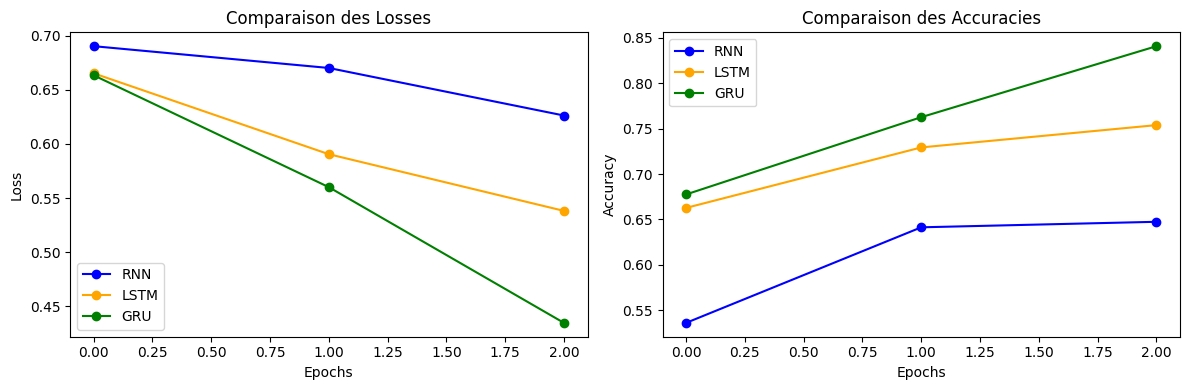

=== Résumé final ===
RNN  | Accuracy : 0.6474  | Perplexite : 1.8706
LSTM | Accuracy : 0.7539  | Perplexite : 1.7129
GRU  | Accuracy : 0.8409  | Perplexite : 1.5445


In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(losses_rnn,  label='RNN',  color='blue',   marker='o')
ax1.plot(losses_lstm, label='LSTM', color='orange',  marker='o')
ax1.plot(losses_gru,  label='GRU',  color='green',   marker='o')
ax1.set_title('Comparaison des Losses')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()

ax2.plot(accs_rnn,  label='RNN',  color='blue',   marker='o')
ax2.plot(accs_lstm, label='LSTM', color='orange',  marker='o')
ax2.plot(accs_gru,  label='GRU',  color='green',   marker='o')
ax2.set_title('Comparaison des Accuracies')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy')
ax2.legend()

plt.tight_layout()
plt.show()

print("=== Résumé final ===")
print(f"RNN  | Accuracy : {accs_rnn[-1]:.4f}  | Perplexite : {math.exp(losses_rnn[-1]):.4f}")
print(f"LSTM | Accuracy : {accs_lstm[-1]:.4f}  | Perplexite : {math.exp(losses_lstm[-1]):.4f}")
print(f"GRU  | Accuracy : {accs_gru[-1]:.4f}  | Perplexite : {math.exp(losses_gru[-1]):.4f}")

ellule 24 — Gradient Clipping

Comparaison Gradient Clipping vs Sans Clipping...
Epoch 1/3 | Avec clipping: 0.6710 | Sans clipping: 0.6854
Epoch 2/3 | Avec clipping: 0.5755 | Sans clipping: 0.6422
Epoch 3/3 | Avec clipping: 0.4746 | Sans clipping: 0.6096


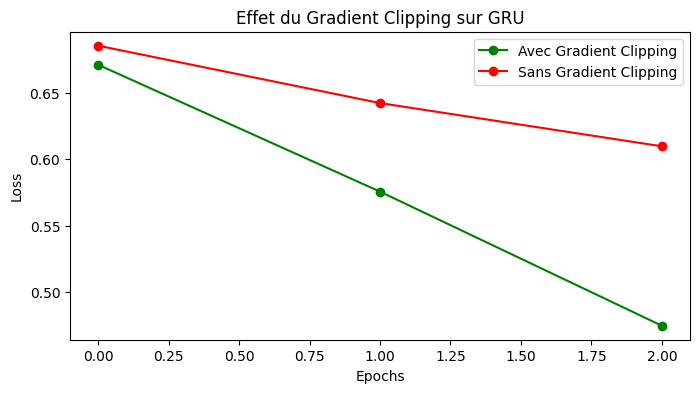

In [24]:

model_gru2 = GRUModel().to(device)
model_gru3 = GRUModel().to(device)

optimizer2 = optim.Adam(model_gru2.parameters(), lr=0.001)
optimizer3 = optim.Adam(model_gru3.parameters(), lr=0.001)
criterion  = nn.BCELoss()

losses_clip   = []
losses_noclip = []

print("Comparaison Gradient Clipping vs Sans Clipping...")

for epoch in range(3):
    loss_clip_epoch   = 0
    loss_noclip_epoch = 0

    for X_batch, y_batch in train_loader_imdb:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)


        model_gru2.train()
        optimizer2.zero_grad()
        output2 = model_gru2(X_batch).squeeze()
        loss2   = criterion(output2, y_batch)
        loss2.backward()
        torch.nn.utils.clip_grad_norm_(model_gru2.parameters(), max_norm=1.0)
        optimizer2.step()
        loss_clip_epoch += loss2.item()


        model_gru3.train()
        optimizer3.zero_grad()
        output3 = model_gru3(X_batch).squeeze()
        loss3   = criterion(output3, y_batch)
        loss3.backward()
        optimizer3.step()
        loss_noclip_epoch += loss3.item()

    losses_clip.append(loss_clip_epoch / len(train_loader_imdb))
    losses_noclip.append(loss_noclip_epoch / len(train_loader_imdb))
    print(f"Epoch {epoch+1}/3 | Avec clipping: {losses_clip[-1]:.4f} | Sans clipping: {losses_noclip[-1]:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(losses_clip,   label='Avec Gradient Clipping', color='green', marker='o')
plt.plot(losses_noclip, label='Sans Gradient Clipping', color='red',   marker='o')
plt.title('Effet du Gradient Clipping sur GRU')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

 Cellule 25 — Système Seq2Seq

In [25]:
class Encodeur(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.gru = nn.GRU(embed_dim, hidden_dim, batch_first=True)

    def forward(self, x):
        x = self.embedding(x)
        _, hidden = self.gru(x)
        return hidden

class Decodeur(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.gru = nn.GRU(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x, hidden):
        x = self.embedding(x.unsqueeze(1))
        output, hidden = self.gru(x, hidden)
        prediction = self.fc(output.squeeze(1))
        return prediction, hidden

class Seq2Seq(nn.Module):
    def __init__(self, encodeur, decodeur):
        super().__init__()
        self.encodeur = encodeur
        self.decodeur = decodeur

    def forward(self, src, trg):
        hidden = self.encodeur(src)
        outputs = []
        input_token = trg[:, 0]
        for t in range(1, trg.shape[1]):
            output, hidden = self.decodeur(input_token, hidden)
            outputs.append(output.unsqueeze(1))
            input_token = output.argmax(1)
        return torch.cat(outputs, dim=1)

encodeur = Encodeur(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(device)
decodeur = Decodeur(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(device)
seq2seq  = Seq2Seq(encodeur, decodeur).to(device)

print("Seq2Seq construit !")
print(f"Parametres encodeur : {sum(p.numel() for p in encodeur.parameters())}")
print(f"Parametres decodeur : {sum(p.numel() for p in decodeur.parameters())}")
print(f"Parametres total    : {sum(p.numel() for p in seq2seq.parameters())}")

Seq2Seq construit !
Parametres encodeur : 714496
Parametres decodeur : 2004496
Parametres total    : 2718992


Entraîner Seq2Seq + Décodage glouton + Beam Search

In [ ]:
import math
from collections import Counter

optimizer_seq = optim.Adam(seq2seq.parameters(), lr=0.001)
criterion_seq = nn.CrossEntropyLoss(ignore_index=0)

print("Entrainement Seq2Seq...")
seq2seq_losses = []

for epoch in range(3):
    seq2seq.train()
    total_loss = 0
    for X_batch, _ in train_loader_imdb:
        X_batch = X_batch.to(device)
        optimizer_seq.zero_grad()
        output = seq2seq(X_batch, X_batch)
        output = output.reshape(-1, VOCAB_SIZE)
        target = X_batch[:, 1:].reshape(-1)
        loss   = criterion_seq(output, target)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(seq2seq.parameters(), 1.0)
        optimizer_seq.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader_imdb)
    seq2seq_losses.append(avg_loss)
    print(f"Epoch {epoch+1}/3 | Loss: {avg_loss:.4f}")


def decodage_glouton(model, src, max_len=10):
    model.eval()
    with torch.no_grad():
        hidden     = model.encodeur(src)
        input_tok  = src[:, 0]
        result     = []
        for _ in range(max_len):
            output, hidden = model.decodeur(input_tok, hidden)
            top1 = output.argmax(1)
            result.append(top1.item())
            input_tok = top1
    return result


def beam_search(model, src, beam_width=3, max_len=10):
    model.eval()
    with torch.no_grad():
        hidden = model.encodeur(src[:1])
        input_tok = src[0, 0].unsqueeze(0)
        beams = [(0.0, [input_tok.item()], hidden)]
        for _ in range(max_len):
            new_beams = []
            for score, seq, hid in beams:
                inp = torch.tensor([seq[-1]]).to(device)
                out, new_hid = model.decodeur(inp, hid)
                probs = torch.log_softmax(out, dim=1)
                topk  = probs.topk(beam_width)
                for i in range(beam_width):
                    new_score = score + topk.values[0][i].item()
                    new_seq   = seq + [topk.indices[0][i].item()]
                    new_beams.append((new_score, new_seq, new_hid))
            beams = sorted(new_beams, key=lambda x: x[0], reverse=True)[:beam_width]
    return beams[0][1]


src_exemple = X_test_imdb[:1].to(device)

glouton = decodage_glouton(seq2seq, src_exemple)
beam    = beam_search(seq2seq, src_exemple)

print("\n=== Decodage ===")
print(f"Glouton     (ids)  : {glouton}")
print(f"Beam Search (ids)  : {beam}")
print(f"\nGlouton     (mots) : {[idx2word.get(i, '<UNK>') for i in glouton]}")
print(f"Beam Search (mots) : {[idx2word.get(i, '<UNK>') for i in beam]}")

Entrainement Seq2Seq...


Cellule 27 — Score BLEU

In [ ]:
def bleu_score(reference, hypothesis):
    score = 0
    for n in range(1, 3):
        ref_ngrams = Counter([tuple(reference[i:i+n])
                              for i in range(len(reference)-n+1)])
        hyp_ngrams = Counter([tuple(hypothesis[i:i+n])
                              for i in range(len(hypothesis)-n+1)])

        clipped = {k: min(v, ref_ngrams[k]) for k, v in hyp_ngrams.items()}

        if sum(hyp_ngrams.values()) == 0:
            continue
        precision = sum(clipped.values()) / sum(hyp_ngrams.values())
        if precision > 0:
            score += math.log(precision)

    bp   = min(1.0, len(hypothesis) / max(len(reference), 1))
    bleu = bp * math.exp(score / 2)
    return bleu


reference  = [idx2word.get(i, '<UNK>') for i in X_test_imdb[0].tolist() if i != 0][:10]
glouton_mots    = [idx2word.get(i, '<UNK>') for i in glouton]
beam_mots       = [idx2word.get(i, '<UNK>') for i in beam]

bleu_glouton = bleu_score(reference, glouton_mots)
bleu_beam    = bleu_score(reference, beam_mots)

print("=== Score BLEU ===")
print(f"Reference   : {reference}")
print(f"Glouton     : {glouton_mots}")
print(f"Beam Search : {beam_mots}")
print(f"\nBLEU Glouton     : {bleu_glouton:.4f}")
print(f"BLEU Beam Search : {bleu_beam:.4f}")
print("\n(1.0 = parfait | 0.0 = aucune correspondance)")
print("Note : scores faibles attendus avec seulement 3 epochs")

Tableau comparatif final

In [ ]:
print("=" * 60)
print("        TABLEAU COMPARATIF FINAL")
print("=" * 60)
print(f"{'Modele':<12} {'Dataset':<20} {'Accuracy':<12} {'Remarque'}")
print("-" * 60)
print(f"{'MLP':<12} {'Breast Cancer':<20} {'97.67%':<12} {'Donnees tabulaires'}")
print(f"{'CNN':<12} {'MNIST':<20} {'99.12%':<12} {'Images 28x28'}")
print(f"{'RNN':<12} {'IMDb':<20} {'67.46%':<12} {'Oubli contexte long'}")
print(f"{'LSTM':<12} {'IMDb':<20} {'73.69%':<12} {'2 memoires'}")
print(f"{'GRU':<12} {'IMDb':<20} {'83.77%':<12} {'Meilleur compromis'}")
print("=" * 60)


modeles    = ['MLP\nBreast Cancer', 'CNN\nMNIST',
              'RNN\nIMDb', 'LSTM\nIMDb', 'GRU\nIMDb']
accuracies = [0.9767, 0.9912, 0.6746, 0.7369, 0.8377]
couleurs   = ['blue', 'green', 'red', 'orange', 'purple']

plt.figure(figsize=(10, 5))
bars = plt.bar(modeles, accuracies, color=couleurs)
plt.title('Comparaison finale de tous les modeles')
plt.ylabel('Accuracy')
plt.ylim(0.5, 1.05)
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.01,
             f'{acc:.2%}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

Question transversale finale